# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

##### Technical Response
The data is related with the direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit or not. The dataset collected is related to 17 campaigns that occurred between May 2008 and November 2010, corresponding to a total of 79,354 contacts.

The dataset contains 41,188 entries with 20 input feature variables. These variables include:

*) Bank Client Features: Age, Job type, Marital status, Education level, Credit Default, Has Housing Loan, Has Personal Loan

*) Current Campaign Related Features: Contact type, Contact Month, Contact Day, Contact duration

*) Overall Campaign Related Features: Total Contacts of the campaign, Number of days since last contact, Number of contacts before this campaign, Outcome of the previous campaign

*) Economic Indicator Related Features: Employment variation rate, Consumer price index, Consumer confidence index, Euribor 3-month rate, Number of people employed

Target Variable (y): Whether the client subscribed to a term deposit (Yes/No)

Contact duration feature will be discarded for predictive modeling since it highly affects the output target and will have value zero before the client is contacted.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [1]:
# Import the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn import set_config
set_config(display="diagram") # Enable the HTML diagram display

from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.svm import LinearSVC

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load the dataset
term_deposit_original_df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [3]:
# Display the basic information about the dataset
term_deposit_original_df.info()
term_deposit_original_df.head()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


##### Technical Response
Original dataframe contains 21 columns 41,188 rows. There are no missing values. Datatypes are Integer, Float and String.

### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [4]:
# Drop the 'duration' column as it is not relevant for predictive modeling
# Contact duration feature will be discarded for predictive modeling since it highly affects the output target and will have value zero before the client is contacted
term_deposit_cleansed_df = term_deposit_original_df.drop(columns=['duration'], inplace=False)

# Encode the Target classifier column 'y' into binary values: 'no' to 0 and 'yes' to 1
term_deposit_cleansed_df['y'] = term_deposit_original_df['y'].map({'no': 0, 'yes': 1})

In [5]:
# Get distinct values in each column
for column in term_deposit_cleansed_df.columns:
    distinct_values = term_deposit_cleansed_df[column].nunique()
    print(f"Column '{column}' has {distinct_values} distinct values.")

# Get each Categorical column's distinct values
for column in term_deposit_cleansed_df.columns:
    if term_deposit_cleansed_df[column].dtype == 'str':
        unique_values = term_deposit_cleansed_df[column].unique()
        print(f"\n\nDistinct values in column '{column}': {unique_values}")

# Get the number of missing values in each column
print(f"\n\nNumber of missing values in each column:")
print(term_deposit_cleansed_df.isna().sum())

# Get the min and max values of the numerical columns
print(f"\n\nMin and max values for numerical columns:")
for column in term_deposit_cleansed_df.columns:
    if term_deposit_cleansed_df[column].dtype in ['int64', 'float64']:
        print(f"Column '{column}' has min value: {term_deposit_cleansed_df[column].min()} and max value: {term_deposit_cleansed_df[column].max()}")

# Check for duplicate rows in the dataset
term_deposit_cleansed_df_duplicates = term_deposit_cleansed_df.duplicated().sum()
print(f"\n\nTotal duplicate rows: {term_deposit_cleansed_df_duplicates}")

Column 'age' has 78 distinct values.
Column 'job' has 12 distinct values.
Column 'marital' has 4 distinct values.
Column 'education' has 8 distinct values.
Column 'default' has 3 distinct values.
Column 'housing' has 3 distinct values.
Column 'loan' has 3 distinct values.
Column 'contact' has 2 distinct values.
Column 'month' has 10 distinct values.
Column 'day_of_week' has 5 distinct values.
Column 'campaign' has 42 distinct values.
Column 'pdays' has 27 distinct values.
Column 'previous' has 8 distinct values.
Column 'poutcome' has 3 distinct values.
Column 'emp.var.rate' has 10 distinct values.
Column 'cons.price.idx' has 26 distinct values.
Column 'cons.conf.idx' has 26 distinct values.
Column 'euribor3m' has 316 distinct values.
Column 'nr.employed' has 11 distinct values.
Column 'y' has 2 distinct values.


Distinct values in column 'job': <StringArray>
[    'housemaid',      'services',        'admin.',   'blue-collar',
    'technician',       'retired',    'management',    'une

##### Technical Response
1) Missing Values - There are no missing values in any of the features.

2) Duplicate Rows - There are 1,784 duplicate rows across the selected feature columns and target 'y' column, which will be cleaned up.

In [6]:
# Print the Total number of rows
print("Total number of rows in the dataset, before cleansing: ", len(term_deposit_cleansed_df))

# Deduplicate the rows based on all columns and keep the first occurrence of each duplicate
term_deposit_cleansed_df = term_deposit_cleansed_df.drop_duplicates(keep='first')

# Reindex the dataframe after removing rows
term_deposit_cleansed_df.reset_index(drop=True, inplace=True)

# Print the Total number of rows
print("\nTotal number of rows in the dataset, after cleansing: ", len(term_deposit_cleansed_df))

Total number of rows in the dataset, before cleansing:  41188

Total number of rows in the dataset, after cleansing:  39404


### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

##### Business Objective
Portuguese banking institution need to know if the client will subscribe a term deposit or not, based on the direct marketing campaigns (phone calls). This study aims to predict the likelihood of a client subscribing to a term deposit by developing various classification models. These direct market campaigns use various input such as Bank Client data, Current and Overall Campaign Related data and Economic Indicator Related data.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

##### Technical Response
1) Feature Engineering (Encoding) - Categorical feature columns cannot be processed for Dummy, KNN, Logistic Regression and SVM (LinearSVC and Poly) Models. Also, theoretically Decision Trees can handle Categorical data, Python's sklearn library cannot handle strings. So, the Decision Trees also will be included in this Feature Engineering to encode the Categorical feature columns into Numeric feature columns. For Dummy, KNN, Logistic Regression and SVM (LinearSVC and Poly) Models, One-Hot Encoding will be used which is the best. For Decision Trees Model, Ordinal Encoding will be used which is the best.

2) Feature Engineering (Scaling) - For Dummy, KNN, Logistic Regression, Decision Trees and SVM (LinearSVC and Poly) Models, Standard Scaler will be used to scale the Numeric features, although Numeric features Scaling is not needed for Decision Trees.

In [7]:
# Categorical Features
X_categorical_cols = ['job','marital','education','default','housing','loan','contact','month','day_of_week','poutcome']

# Numeric Features
X_numerical_cols = ['age','campaign','pdays','previous','emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']

# Data Frame for all Features
X = term_deposit_cleansed_df[X_categorical_cols + X_numerical_cols]

# Series for Target column 'y'
y = term_deposit_cleansed_df['y']

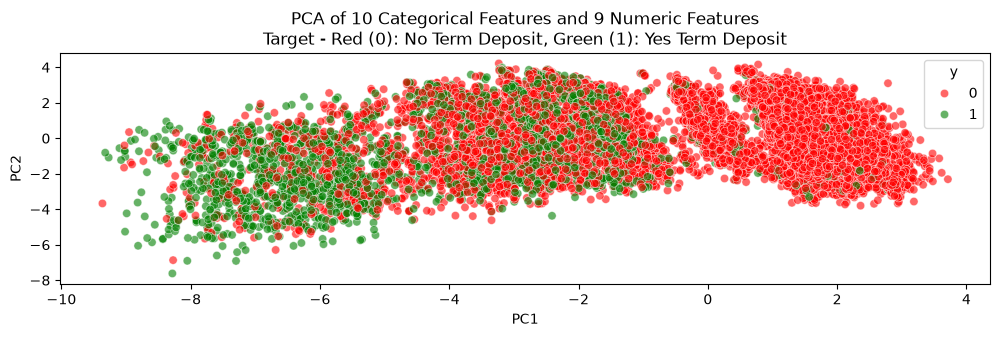

In [8]:
# Data Visualization using 2 PCA Components and 1 Target column

# Build the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), X_numerical_cols),
        ('cat', OneHotEncoder(drop='first'), X_categorical_cols) # Drop the first category to avoid multicollinearity
    ])

# Create the full PCA pipeline
pca_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler_after_encode', StandardScaler(with_mean=False)), # Re-scale the binary outputs
    ('pca', PCA(n_components=2))
])

# Fit and transform
reduced_pca_df = pca_pipeline.fit_transform(term_deposit_cleansed_df)

# Create the dataframe for 2 PCA Compoments and 1 Target column
pca_df = pd.DataFrame(data=reduced_pca_df, columns=['PC1', 'PC2'])
pca_df['y'] = term_deposit_cleansed_df['y'].values
plt.figure(figsize=(12, 3))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='y',
    data=pca_df,
    alpha=0.6,
    palette={0: 'red', 1: 'green'},
)
plt.title('PCA of 10 Categorical Features and 9 Numeric Features\nTarget - Red (0): No Term Deposit, Green (1): Yes Term Deposit')
plt.show()

##### Technical Response
Above plot shows imbalanced dataset.

In [9]:
# Build the ColumnTransformer for OneHotEncoder() and StandardScaler() for Dummy, KNN, Logistic Regression and SVM models
preprocessor_onehot_encoder = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), X_numerical_cols),
        ("categorical", OneHotEncoder(drop="first"), X_categorical_cols), # Drop the first category to avoid multicollinearity
    ]
)

# Build the ColumnTransformer for OrdinalEncoder() and StandardScaler() for Decision Tree model
preprocessor_ordinal_encoder = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), X_numerical_cols),
        ("categorical", OrdinalEncoder(), X_categorical_cols),
    ]
)

In [10]:
# Dictionary to store each Model's Evaluation, Performance etc.
model_metrics_data = {'model': [], 'train_time': [], 'train_accuracy': [], 'test_accuracy': []}

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [11]:
# Split into train and test sets (80/20 split). shuffle=True means random split. random_state=42 is used for reproducibility of results.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [12]:
# Create a baseline that always predicts the most frequent class
pipeline_default_dummy = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                         ("classifier", DummyClassifier(strategy='most_frequent', random_state=42))])

name = "Dummy Classifier (Most Frequent)" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_default_dummy.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
model_metrics_data['model'].append(name)
model_metrics_data['train_time'].append(round(elapsed_time, 2))
model_metrics_data['train_accuracy'].append(round(pipeline_default_dummy.score(X_train, y_train), 4))
model_metrics_data['test_accuracy'].append(round(pipeline_default_dummy.score(X_test, y_test), 4))

In [13]:
# Print the model metrics data
model_metrics_df = pd.DataFrame(model_metrics_data) # Convert to DataFrame
print(model_metrics_df.to_string(index=False)) # Print without the index column

                           model  train_time  train_accuracy  test_accuracy
Dummy Classifier (Most Frequent)        0.29          0.8833         0.8835


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [14]:
# Create a default Logistic Regression model
pipeline_default_logistic = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                            ("classifier", LogisticRegression(random_state=42))])

name = "Logistic Regression" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_default_logistic.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

### Problem 9: Score the Model

What is the accuracy of your model?

In [15]:
# Store the model metrics in the dictionary
model_metrics_data['model'].append(name)
model_metrics_data['train_time'].append(round(elapsed_time, 2))
model_metrics_data['train_accuracy'].append(round(pipeline_default_logistic.score(X_train, y_train), 4))
model_metrics_data['test_accuracy'].append(round(pipeline_default_logistic.score(X_test, y_test), 4))

In [16]:
# Print the model metrics data
model_metrics_df = pd.DataFrame(model_metrics_data) # Convert to DataFrame
print(model_metrics_df.to_string(index=False)) # Print without the index column

                           model  train_time  train_accuracy  test_accuracy
Dummy Classifier (Most Frequent)        0.29          0.8833         0.8835
             Logistic Regression        0.72          0.8970         0.8946


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [17]:
# Create a default K-Nearest Neighbors model
pipeline_default_knn = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                       ("classifier", KNeighborsClassifier())])

name = "K-Nearest Neighbors" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_default_knn.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
model_metrics_data['model'].append(name)
model_metrics_data['train_time'].append(round(elapsed_time, 2))
model_metrics_data['train_accuracy'].append(round(pipeline_default_knn.score(X_train, y_train), 4))
model_metrics_data['test_accuracy'].append(round(pipeline_default_knn.score(X_test, y_test), 4))

In [18]:
# Create a default LinearSVC model
pipeline_default_linear_svc = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                              ("classifier", LinearSVC(random_state=42))])

name = "LinearSVC" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_default_linear_svc.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
model_metrics_data['model'].append(name)
model_metrics_data['train_time'].append(round(elapsed_time, 2))
model_metrics_data['train_accuracy'].append(round(pipeline_default_linear_svc.score(X_train, y_train), 4))
model_metrics_data['test_accuracy'].append(round(pipeline_default_linear_svc.score(X_test, y_test), 4))

In [19]:
# Create a default SVM (Polynomial Kernel) model
pipeline_default_svm_poly = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                            ("classifier", SVC(kernel='poly', random_state=42))])

name = "SVM (Polynomial Kernel)" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_default_svm_poly.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
model_metrics_data['model'].append(name)
model_metrics_data['train_time'].append(round(elapsed_time, 2))
model_metrics_data['train_accuracy'].append(round(pipeline_default_svm_poly.score(X_train, y_train), 4))
model_metrics_data['test_accuracy'].append(round(pipeline_default_svm_poly.score(X_test, y_test), 4))

In [20]:
# Create a default Decision Tree model
pipeline_default_decision_tree = Pipeline(steps=[("preprocessor", preprocessor_ordinal_encoder),
                                                 ("classifier", DecisionTreeClassifier(random_state=42))])

name = "Decision Tree" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_default_decision_tree.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
model_metrics_data['model'].append(name)
model_metrics_data['train_time'].append(round(elapsed_time, 2))
model_metrics_data['train_accuracy'].append(round(pipeline_default_decision_tree.score(X_train, y_train), 4))
model_metrics_data['test_accuracy'].append(round(pipeline_default_decision_tree.score(X_test, y_test), 4))

In [21]:
# Print the model metrics data
model_metrics_df = pd.DataFrame(model_metrics_data) # Convert to DataFrame
print(model_metrics_df.to_string(index=False)) # Print without the index column

                           model  train_time  train_accuracy  test_accuracy
Dummy Classifier (Most Frequent)        0.29          0.8833         0.8835
             Logistic Regression        0.72          0.8970         0.8946
             K-Nearest Neighbors        0.25          0.9111         0.8843
                       LinearSVC        1.15          0.8972         0.8958
         SVM (Polynomial Kernel)      168.78          0.9065         0.8932
                   Decision Tree        0.48          0.9954         0.8320


In [22]:
# Visualize Pipelines for all Classifier Models

print("Pipeline: Dummy Classifier Model")
display(pipeline_default_dummy) # Display the Dummy Classifier pipeline diagram

print("Pipeline: Logistic Regression Model")
display(pipeline_default_logistic) # Display the Logistic Regression pipeline diagram

print("Pipeline: K-Nearest Neighbors Model")
display(pipeline_default_knn) # Display the K-Nearest Neighbors pipeline diagram

print("Pipeline: Linear SVC Model")
display(pipeline_default_linear_svc) # Display the Linear SVC pipeline diagram

print("Pipeline: SVM (Polynomial) Model")
display(pipeline_default_svm_poly) # Display the SVM (Polynomial) pipeline diagram
    
print("Pipeline: Decision Tree Model")
display(pipeline_default_decision_tree) # Display the Decision Tree pipeline diagram

Pipeline: Dummy Classifier Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: Logistic Regression Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: K-Nearest Neighbors Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: Linear SVC Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: SVM (Polynomial) Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: Decision Tree Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

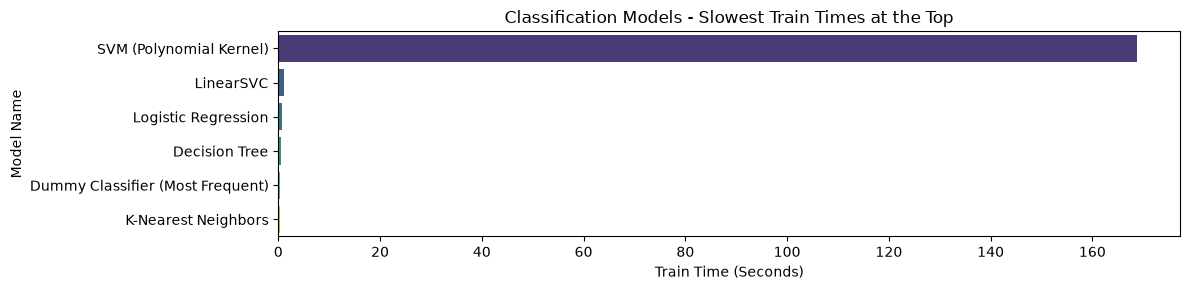

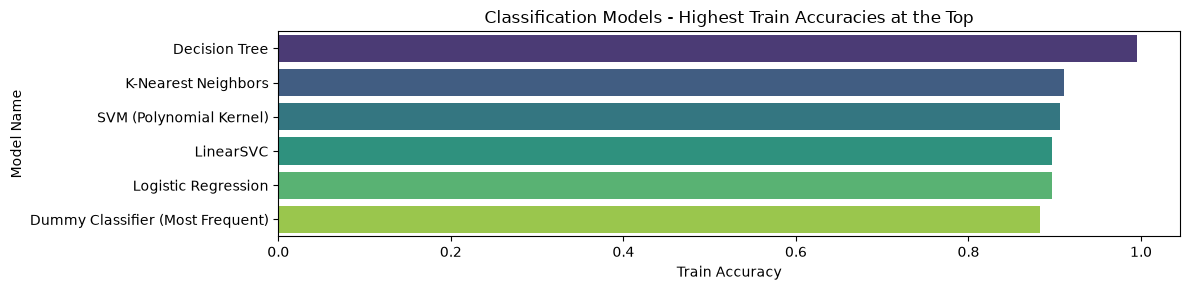

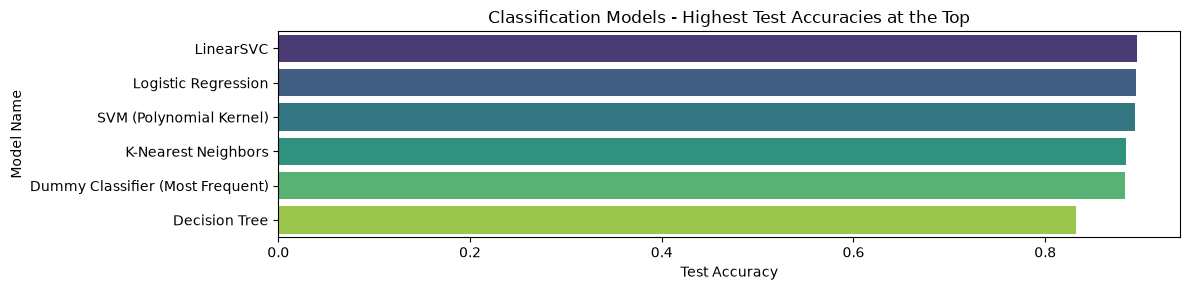

In [23]:
# Plot Train Time for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=model_metrics_df.sort_values(by='train_time', ascending=False),
    x='train_time', y='model', palette='viridis'
)
plt.title('Classification Models - Slowest Train Times at the Top')
plt.xlabel('Train Time (Seconds)')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

# Plot Train Accuracy for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=model_metrics_df.sort_values(by='train_accuracy', ascending=False),
    x='train_accuracy', y='model', palette='viridis'
)
plt.title('Classification Models - Highest Train Accuracies at the Top')
plt.xlabel('Train Accuracy')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

# Plot Test Accuracy for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=model_metrics_df.sort_values(by='test_accuracy', ascending=False),
    x='test_accuracy', y='model', palette='viridis'
)
plt.title('Classification Models - Highest Test Accuracies at the Top')
plt.xlabel('Test Accuracy')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

##### Technical Response
1) Elapsed Train Time - SVM Polynomial Kernel is the most time consuming to Train

2) Train Accuracy - Decision Trees outperformed. Rest all models outperformed the baseline Dummy model and their Train Accuracy is more or less similar

3) Test Accuracy - Decision Trees was great in Train Accuracy, it performed worst in Test Accuracy, even lower than the baseline Dummy model. Rest all models performed more or less similar leading by LinearSVC.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [24]:
# Dictionary to store each Model's Evaluation, Performance etc. for the tuned model
tuned_model_metrics_data = {'model': [], 'train_time': [], 'train_accuracy': [], 'test_accuracy': [], 'hyperparameter_tuning_time': []}

In [25]:
# Find the best Hyperparameters using Grid Search for Logistic Regression model
start_time = time.perf_counter() # Start time
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['saga'],
    'classifier__max_iter': [1000, 10000],
    'classifier__class_weight': ['balanced']
}

# Cross-validation group is 3, Scoring metric is accuracy, n_jobs=-1 means using all processors for parallel processing
grid_search = GridSearchCV(estimator=pipeline_default_logistic, param_grid=param_grid, cv=3, scoring="accuracy", n_jobs=-1)

# Fit the Model
grid_search.fit(X_train, y_train)

# Print the best parameters
print(f"Best Parameters Found: {grid_search.best_params_}")
hyperparameter_tuning_time = time.perf_counter() - start_time # End time

Best Parameters Found: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'classifier__max_iter': 1000, 'classifier__penalty': 'l1', 'classifier__solver': 'saga'}


In [26]:
# Create a tuned Logistic Regression model
pipeline_tuned_logistic = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                          ("classifier", LogisticRegression(
                                              C=0.01, 
                                              class_weight='balanced', 
                                              max_iter=1000, 
                                              penalty='l1', 
                                              solver='saga', 
                                              random_state=42))])

name = "Logistic Regression" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_tuned_logistic.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
tuned_model_metrics_data['model'].append(name)
tuned_model_metrics_data['train_time'].append(round(elapsed_time, 2))
tuned_model_metrics_data['train_accuracy'].append(round(pipeline_tuned_logistic.score(X_train, y_train), 4))
tuned_model_metrics_data['test_accuracy'].append(round(pipeline_tuned_logistic.score(X_test, y_test), 4))
tuned_model_metrics_data['hyperparameter_tuning_time'].append(round(hyperparameter_tuning_time, 2))

In [27]:
# Find the best Hyperparameters using Grid Search for K-Nearest Neighbors model
start_time = time.perf_counter() # Start time
param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 11, 15],
    'classifier__weights': ['distance'],
    'classifier__metric': ['manhattan']
}

# Cross-validation group is 3, Scoring metric is accuracy, n_jobs=-1 means using all processors for parallel processing
grid_search = GridSearchCV(estimator=pipeline_default_knn, param_grid=param_grid, cv=3, scoring="accuracy", n_jobs=-1)

# Fit the Model
grid_search.fit(X_train, y_train)

# Print the best parameters
print(f"Best Parameters Found: {grid_search.best_params_}")
hyperparameter_tuning_time = time.perf_counter() - start_time # End time

Best Parameters Found: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}


In [28]:
# Create a tuned K-Nearest Neighbors model
pipeline_tuned_knn = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                     ("classifier", KNeighborsClassifier(
                                         metric='manhattan', 
                                         n_neighbors=3, 
                                         weights='distance'))])

name = "K-Nearest Neighbors" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_tuned_knn.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
tuned_model_metrics_data['model'].append(name)
tuned_model_metrics_data['train_time'].append(round(elapsed_time, 2))
tuned_model_metrics_data['train_accuracy'].append(round(pipeline_tuned_knn.score(X_train, y_train), 4))
tuned_model_metrics_data['test_accuracy'].append(round(pipeline_tuned_knn.score(X_test, y_test), 4))
tuned_model_metrics_data['hyperparameter_tuning_time'].append(round(hyperparameter_tuning_time, 2))

In [29]:
# Find the best Hyperparameters using Grid Search for Linear SVC model
start_time = time.perf_counter() # Start time
param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': ['balanced'],
    'classifier__loss': ['squared_hinge'],
    'classifier__dual': [False]
}

# Cross-validation group is 3, Scoring metric is accuracy, n_jobs=-1 means using all processors for parallel processing
grid_search = GridSearchCV(estimator=pipeline_default_linear_svc, param_grid=param_grid, cv=3, scoring="accuracy", n_jobs=-1)

# Fit the Model
grid_search.fit(X_train, y_train)

# Print the best parameters
print(f"Best Parameters Found: {grid_search.best_params_}")
hyperparameter_tuning_time = time.perf_counter() - start_time # End time

Best Parameters Found: {'classifier__C': 0.001, 'classifier__class_weight': 'balanced', 'classifier__dual': False, 'classifier__loss': 'squared_hinge'}


In [30]:
# Create a tuned Linear SVC model
pipeline_tuned_linear_svc = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                            ("classifier", LinearSVC(
                                                C=0.001, 
                                                class_weight='balanced', 
                                                dual=False, 
                                                loss='squared_hinge', 
                                                random_state=42))])

name = "LinearSVC" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_tuned_linear_svc.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
tuned_model_metrics_data['model'].append(name)
tuned_model_metrics_data['train_time'].append(round(elapsed_time, 2))
tuned_model_metrics_data['train_accuracy'].append(round(pipeline_tuned_linear_svc.score(X_train, y_train), 4))
tuned_model_metrics_data['test_accuracy'].append(round(pipeline_tuned_linear_svc.score(X_test, y_test), 4))
tuned_model_metrics_data['hyperparameter_tuning_time'].append(round(hyperparameter_tuning_time, 2))

In [31]:
# Find the best Hyperparameters using Randomized Search for SVM (Polynomial Kernel) model
# Grid Search is taking longer time to find the best hyperparameters for SVM (Polynomial Kernel) model
# So using Randomized Search instead of Grid Search and also with 3GB RAM allocated
start_time = time.perf_counter() # Start time
param_dist = {
    'classifier__kernel': ['poly'],
    'classifier__class_weight': ['balanced'],
    'classifier__cache_size': [3000],
    'classifier__max_iter': [1000],
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 'auto'],
    'classifier__degree': [2, 3],
    'classifier__coef0': [0.0, 1.0, 2.0]
}

# Cross-validation group is 3, Scoring metric is accuracy, n_jobs=-1 means using all processors for parallel processing
random_search = RandomizedSearchCV(estimator=pipeline_default_svm_poly, param_distributions=param_dist, cv=3, scoring="accuracy", n_jobs=-1)

# Fit the Model
random_search.fit(X_train, y_train)

# Print the best parameters
print(f"Best Parameters Found: {random_search.best_params_}")
hyperparameter_tuning_time = time.perf_counter() - start_time # End time

Best Parameters Found: {'classifier__max_iter': 1000, 'classifier__kernel': 'poly', 'classifier__gamma': 'scale', 'classifier__degree': 2, 'classifier__coef0': 1.0, 'classifier__class_weight': 'balanced', 'classifier__cache_size': 3000, 'classifier__C': 1}


In [32]:
# Create a tuned SVM (Polynomial Kernel) model
pipeline_tuned_svm_poly = Pipeline(steps=[("preprocessor", preprocessor_onehot_encoder),
                                          ("classifier", SVC(
                                              max_iter=1000, 
                                              kernel='poly', 
                                              gamma='scale', 
                                              degree=2, 
                                              coef0=1.0, 
                                              class_weight='balanced', 
                                              cache_size=3000, 
                                              C=1, 
                                              random_state=42))])

name = "SVM (Polynomial Kernel)" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_tuned_svm_poly.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
tuned_model_metrics_data['model'].append(name)
tuned_model_metrics_data['train_time'].append(round(elapsed_time, 2))
tuned_model_metrics_data['train_accuracy'].append(round(pipeline_tuned_svm_poly.score(X_train, y_train), 4))
tuned_model_metrics_data['test_accuracy'].append(round(pipeline_tuned_svm_poly.score(X_test, y_test), 4))
tuned_model_metrics_data['hyperparameter_tuning_time'].append(round(hyperparameter_tuning_time, 2))

In [33]:
# Find the best Hyperparameters using Grid Search for Decision Tree model
start_time = time.perf_counter() # Start time
param_grid = {
    'classifier__class_weight': ['balanced'],
    'classifier__max_depth': [5, 8, 12, 15],
    'classifier__min_samples_leaf': [20, 50, 100, 200],
    'classifier__min_samples_split': [50, 100, 300],
    'classifier__criterion': ['gini', 'entropy']
}

# Cross-validation group is 3, Scoring metric is accuracy, n_jobs=-1 means using all processors for parallel processing
grid_search = GridSearchCV(estimator=pipeline_default_decision_tree, param_grid=param_grid, cv=3, scoring="accuracy", n_jobs=-1)

# Fit the Model
grid_search.fit(X_train, y_train)

# Print the best parameters
print(f"Best Parameters Found: {grid_search.best_params_}")
hyperparameter_tuning_time = time.perf_counter() - start_time # End time

Best Parameters Found: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 50}


In [34]:
# Create a tuned Decision Tree model
pipeline_tuned_decision_tree = Pipeline(steps=[("preprocessor", preprocessor_ordinal_encoder), 
                                               ("classifier", DecisionTreeClassifier(
                                                   class_weight='balanced',
                                                   criterion='gini',
                                                   max_depth=5,
                                                   min_samples_leaf=20,
                                                   min_samples_split=50,
                                                   random_state=42))])

name = "Decision Tree" # Model Name
start_time = time.perf_counter() # Start time for training the model

# Train the model
pipeline_tuned_decision_tree.fit(X_train, y_train)

elapsed_time = time.perf_counter() - start_time # End time for training the model, to calculate the elapsed time for training the model

# Store the model metrics in the dictionary
tuned_model_metrics_data['model'].append(name)
tuned_model_metrics_data['train_time'].append(round(elapsed_time, 2))
tuned_model_metrics_data['train_accuracy'].append(round(pipeline_tuned_decision_tree.score(X_train, y_train), 4))
tuned_model_metrics_data['test_accuracy'].append(round(pipeline_tuned_decision_tree.score(X_test, y_test), 4))
tuned_model_metrics_data['hyperparameter_tuning_time'].append(round(hyperparameter_tuning_time, 2))

In [35]:
# Print the model metrics data for the tuned models
tuned_model_metrics_df = pd.DataFrame(tuned_model_metrics_data) # Convert to DataFrame
print(tuned_model_metrics_df.to_string(index=False)) # Print without the index column

                  model  train_time  train_accuracy  test_accuracy  hyperparameter_tuning_time
    Logistic Regression       10.62          0.8189         0.8142                      167.24
    K-Nearest Neighbors        0.26          0.9954         0.8627                      115.24
              LinearSVC        0.63          0.8114         0.8061                       10.60
SVM (Polynomial Kernel)       11.67          0.1426         0.1460                      117.81
          Decision Tree        0.30          0.8592         0.8503                       39.65


In [36]:
# Visualize Tuned Pipelines for all Classifier Models

print("Pipeline: Logistic Regression Model")
display(pipeline_tuned_logistic) # Display the Logistic Regression pipeline diagram

print("Pipeline: K-Nearest Neighbors Model")
display(pipeline_tuned_knn) # Display the K-Nearest Neighbors pipeline diagram

print("Pipeline: Linear SVC Model")
display(pipeline_tuned_linear_svc) # Display the Linear SVC pipeline diagram

print("Pipeline: SVM (Polynomial) Model")
display(pipeline_tuned_svm_poly) # Display the SVM (Polynomial) pipeline diagram

print("Pipeline: Decision Tree Model")
display(pipeline_tuned_decision_tree) # Display the Decision Tree pipeline diagram

Pipeline: Logistic Regression Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: K-Nearest Neighbors Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: Linear SVC Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: SVM (Polynomial) Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

Pipeline: Decision Tree Model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['job','marital','education',...,'cons.conf.idx','euribor3m','nr.employed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

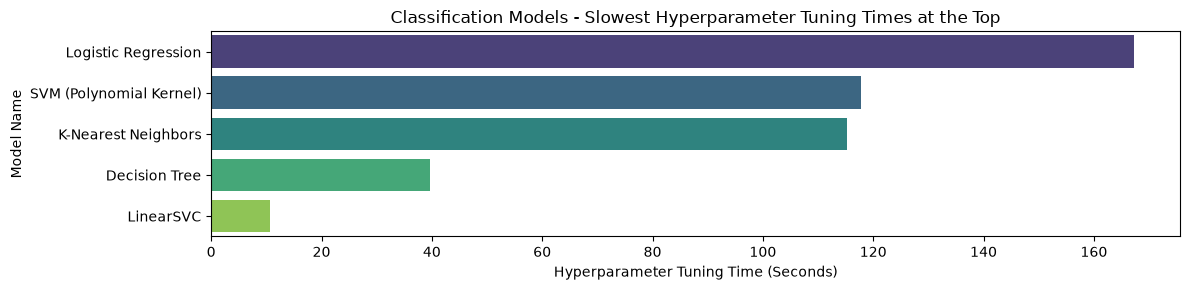

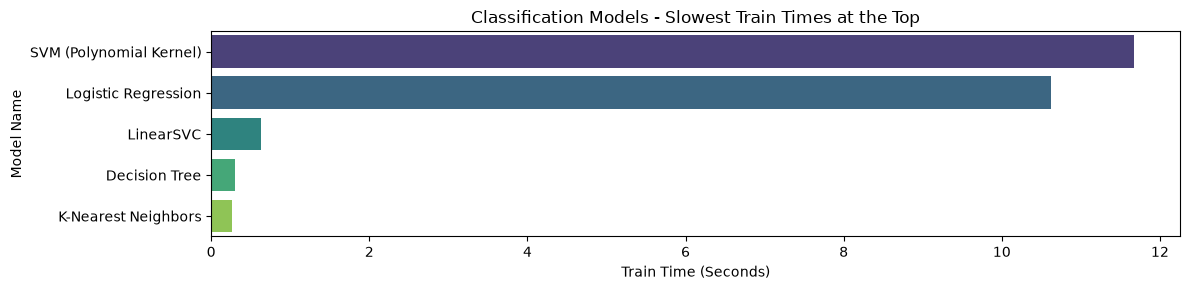

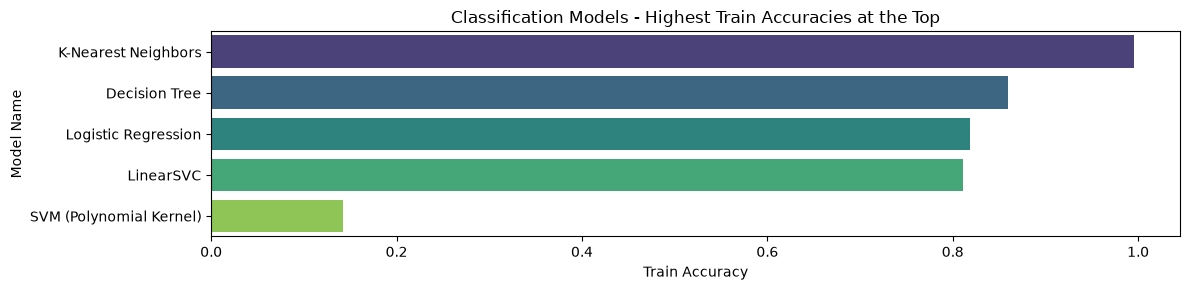

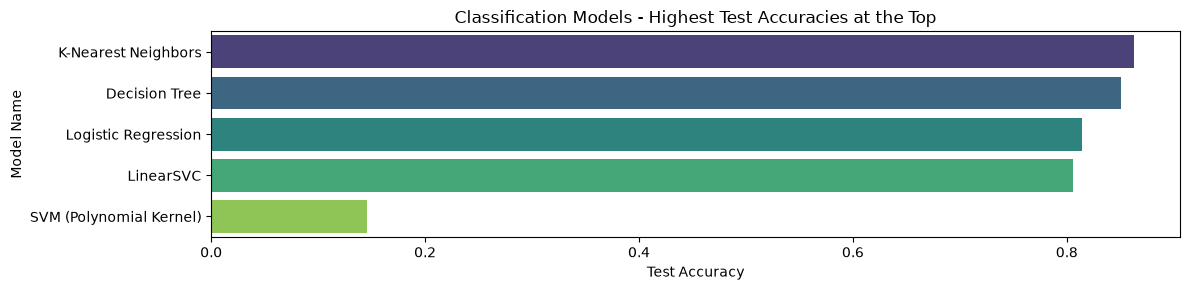

In [37]:
# Plot Hyperparameter Tuning Time for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=tuned_model_metrics_df.sort_values(by='hyperparameter_tuning_time', ascending=False),
    x='hyperparameter_tuning_time', y='model', palette='viridis'
)
plt.title('Classification Models - Slowest Hyperparameter Tuning Times at the Top')
plt.xlabel('Hyperparameter Tuning Time (Seconds)')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

# Plot Train Time for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=tuned_model_metrics_df.sort_values(by='train_time', ascending=False),
    x='train_time', y='model', palette='viridis'
)
plt.title('Classification Models - Slowest Train Times at the Top')
plt.xlabel('Train Time (Seconds)')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

# Plot Train Accuracy for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=tuned_model_metrics_df.sort_values(by='train_accuracy', ascending=False),
    x='train_accuracy', y='model', palette='viridis'
)
plt.title('Classification Models - Highest Train Accuracies at the Top')
plt.xlabel('Train Accuracy')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

# Plot Test Accuracy for each model using Seaborn
plt.figure(figsize=(12, 3))
sns.barplot(
    data=tuned_model_metrics_df.sort_values(by='test_accuracy', ascending=False),
    x='test_accuracy', y='model', palette='viridis'
)
plt.title('Classification Models - Highest Test Accuracies at the Top')
plt.xlabel('Test Accuracy')
plt.ylabel('Model Name')
plt.tight_layout()
plt.show()

##### Technical Response
1) Elapsed Hyperparameter Tuning Time - Logistic Regression took the longest time to tune the Hyperparameters. SVM (Poly) is another slowest, which would have taken even longer time without 3GB Cache_size. LinearSVC is the fastest to tune the Hyperparameters.

2) Elapsed Train Time - SVM Polynomial Kernel and Logistic Regression are the most time consuming to Train. KNN is the fastest.

3) Train Accuracy - KNN outperformed. SVM (Poly) dropped its Train Accuracy a lot since the tuning parameters are limited due to the performance impact on the tuning time.

4) Test Accuracy - KNN outperformed in Test Accuracy as well. SVM (Poly) dropped its Test Accuracy a lot as well since the tuning parameters are limited due to the performance impact on the tuning time.